# Eigensolvers: `ground_state`, `spectrum`, `fermionic_ground_state`, `fermionic_spectrum`

Four entry points in `qaravan.applications.algorithms`:

| function | takes | sectors it understands |
|---|---|---|
| `ground_state` | any qubit `Hamiltonian` | `fixed_particle_number`, or an explicit `sector` |
| `spectrum` | any qubit `Hamiltonian` | same, plus `num_eigenvalues` |
| `fermionic_ground_state` | `FermionicHamiltonian` + `FermionicEncoding` | above, plus `fixed_spin_numbers` |
| `fermionic_spectrum` | `FermionicHamiltonian` + `FermionicEncoding` | same, plus `num_eigenvalues` |

Spin is the default degree of freedom here, so the qubit-level pair keep the bare names. The
fermionic pair are thin wrappers: they encode, work out the sector, and delegate.

**Methods.** `"naive"` is dense `eigh`/`eigvalsh` — the whole spectrum, robust at any size.
`"naive_lanczos"` is `eigsh(k=num_eigenvalues)`; it skips computing the levels you did not ask
for, but still builds the dense $2^n \times 2^n$ matrix first. `"lanczos"` is reserved for the
matrix-free solver and currently raises.

This notebook checks the things the unit tests *cannot*: absolute physics, not internal
consistency.

Scope: this is about the *solvers*. Correctness of the Fermi-Hubbard model itself — its
spectrum, the dimer analytics, PBC — lives in `fermi_hubbard.ipynb`; §1 below uses FH only as
a vehicle for exercising every spin sector.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from qaravan.applications.algorithms import (
    fermionic_ground_state,
    fermionic_spectrum,
    ground_state,
    spectrum,
)
from qaravan.core.fermions import FermionicEncoding, number
from qaravan.core.hamiltonians import (
    TFI,
    FermiHubbard1D,
    FermionicHamiltonian,
    Heisenberg1D,
    interleaved_mode_order,
)

## 1. Absolute check: $U=0$ Fermi-Hubbard against free fermions

At $U=0$ the Hubbard model is a pair of independent tight-binding chains. For an open chain of
$L$ sites with $H = -t\sum(c^\dagger_j c_{j+1} + \mathrm{h.c.})$ the single-particle levels are

$$\varepsilon_k = -2t\cos\!\left(\frac{k\pi}{L+1}\right), \qquad k = 1,\dots,L,$$

and the ground energy in the $(N_\uparrow, N_\downarrow)$ sector is the sum of the $N_\uparrow$
lowest levels plus the $N_\downarrow$ lowest. This is an *absolute* benchmark: it never calls
`eigh`, so it cannot agree with the solver by sharing a bug.

In [2]:
def free_fermion_energy(num_sites, t, num_up, num_down):
    """Sum of occupied levels; open chain has eps_k = -2t cos(k pi/(L+1))."""
    levels = np.sort(-2 * t * np.cos(np.pi * np.arange(1, num_sites + 1) / (num_sites + 1)))
    return levels[:num_up].sum() + levels[:num_down].sum()


worst = 0.0
for num_sites in [2, 3, 4]:
    fh = FermiHubbard1D(num_fermionic_sites=num_sites, t=1.0, U=0.0, mu=0.0)
    encoding = FermionicEncoding("jordan_wigner", num_modes=2 * num_sites)
    for num_up in range(num_sites + 1):
        for num_down in range(num_sites + 1):
            got = fermionic_spectrum(
                fh, encoding, num_eigenvalues=1, fixed_spin_numbers=(num_up, num_down)
            )[0]
            want = free_fermion_energy(num_sites, 1.0, num_up, num_down)
            worst = max(worst, abs(got - want))

print(f"worst deviation over all 51 (L, N_up, N_down) combinations: {worst:.2e}")

worst deviation over all 51 (L, N_up, N_down) combinations: 3.55e-15


Every sector matches, **including asymmetric ones like $(2,1)$**. That matters: the spin-sector
machinery has to place the up and down registers on the right qubits, and an up$\leftrightarrow$down
swap is invisible in symmetric sectors like $(1,1)$. Here it would show up immediately.

## 2. Where the up/down qubits come from

A `FermionicHamiltonian` is defined on abstract modes and knows nothing about qubits. The
canonical spinful labelling is modes $[0,M)$ up and $[M,2M)$ down; the `FermionicEncoding`
carries the mode $\to$ qubit permutation. `spin_qubits()` composes the two, so the *same*
Hamiltonian lands on different qubits under different layouts.

In [3]:
for label, mode_order in [("stacked", None), ("interleaved", interleaved_mode_order(3))]:
    encoding = FermionicEncoding("jordan_wigner", num_modes=6, mode_order=mode_order)
    up, down = encoding.spin_qubits()
    print(f"{label:12s} up qubits {up}   down qubits {down}")

stacked      up qubits [0, 1, 2]   down qubits [3, 4, 5]
interleaved  up qubits [0, 2, 4]   down qubits [1, 3, 5]


Physics must not depend on that choice. Same model, same sector, two layouts:

In [4]:
fh = FermiHubbard1D(num_fermionic_sites=3, t=1.0, U=2.0)
for label, mode_order in [("stacked", None), ("interleaved", interleaved_mode_order(3))]:
    encoding = FermionicEncoding("jordan_wigner", num_modes=6, mode_order=mode_order)
    energy = fermionic_spectrum(
        fh, encoding, num_eigenvalues=1, fixed_spin_numbers=(2, 1)
    )[0]
    print(f"{label:12s} E(2,1) = {energy:.12f}")

stacked      E(2,1) = -1.820089374375
interleaved  E(2,1) = -1.820089374375


### Verify the sector by hand

The returned state should have zero amplitude on any basis state with the wrong occupation.
Check that directly from bitstrings, without trusting the solver's own masks. Note qubit $q$ is
character $q$ of the bitstring, i.e. **qubit 0 is the most significant bit** — that convention
is what the mask arithmetic has to respect.

In [5]:
encoding = FermionicEncoding("jordan_wigner", num_modes=6)   # stacked: up = 0,1,2
sv = fermionic_ground_state(fh, encoding, fixed_spin_numbers=(2, 1))
amplitudes = sv.to_array()

leak, weight = 0.0, 0.0
for index in range(2**6):
    bits = format(index, "06b")
    num_up = sum(bits[q] == "1" for q in [0, 1, 2])
    num_down = sum(bits[q] == "1" for q in [3, 4, 5])
    if (num_up, num_down) == (2, 1):
        weight += abs(amplitudes[index]) ** 2
    else:
        leak = max(leak, abs(amplitudes[index]))

print(f"largest amplitude outside the (2,1) sector: {leak:.2e}")
print(f"probability inside the sector:              {weight:.12f}")

largest amplitude outside the (2,1) sector: 0.00e+00
probability inside the sector:              1.000000000000


The check above is deliberately written from bitstrings so it does not trust the library. For
everyday use there is `NumberOperator`, which under Jordan-Wigner is
$N_S = \frac{|S|}{2}\mathbb{I} - \frac{1}{2}\sum_{q \in S} Z_q$. Handing it a qubit subset gives
$\langle N_\uparrow \rangle$ and $\langle N_\downarrow \rangle$ separately — the thing a plain
popcount over the whole register cannot resolve.

In [6]:
from qaravan.core.observables import NumberOperator

up_qubits, down_qubits = encoding.spin_qubits()
print(f"total    <N>      = {sv.expectation(NumberOperator(6)).real:.10f}")
print(f"up       <N_up>   = {sv.expectation(NumberOperator(6, up_qubits)).real:.10f}")
print(f"down     <N_down> = {sv.expectation(NumberOperator(6, down_qubits)).real:.10f}")

total    <N>      = 3.0000000000
up       <N_up>   = 2.0000000000
down     <N_down> = 1.0000000000


## 3. Spin sectors select different physics

$(2,1)$ and $(1,1)$ are genuinely different states, and the gap between them moves with $U$.
The plain Hubbard model is spin-flip symmetric, so $(2,1)$ and $(1,2)$ are degenerate — adding a
field on the up modes only breaks that, which is the sharpest test that the two registers are
not being confused.

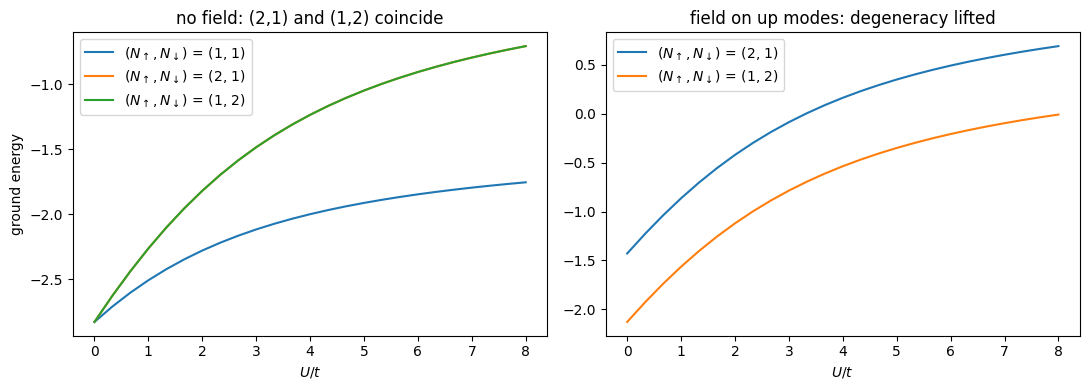

zero-field  |E(2,1) - E(1,2)| = 5.551115123125783e-16
with field  |E(2,1) - E(1,2)| = 0.7000000000000073


In [7]:
def zeeman_hubbard(num_sites, U, zeeman):
    """Hubbard plus a field on the up modes only, breaking (n_up, n_dn) <-> (n_dn, n_up)."""
    fh = FermiHubbard1D(num_fermionic_sites=num_sites, t=1.0, U=U)
    terms = list(fh.terms) + [zeeman * number(mode) for mode in range(num_sites)]
    return FermionicHamiltonian(terms, 2 * num_sites)


encoding = FermionicEncoding("jordan_wigner", num_modes=6)
u_values = np.linspace(0.0, 8.0, 25)
curves = {sector: [] for sector in [(1, 1), (2, 1), (1, 2)]}

for U in u_values:
    ham = zeeman_hubbard(3, U, zeeman=0.0)
    for sector in curves:
        curves[sector].append(
            fermionic_spectrum(ham, encoding, num_eigenvalues=1, fixed_spin_numbers=sector)[0]
        )

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for sector, values in curves.items():
    axes[0].plot(u_values, values, label=f"$(N_\\uparrow,N_\\downarrow)$ = {sector}")
axes[0].set_xlabel("$U/t$"); axes[0].set_ylabel("ground energy")
axes[0].set_title("no field: (2,1) and (1,2) coincide"); axes[0].legend()

split = {sector: [] for sector in [(2, 1), (1, 2)]}
for U in u_values:
    ham = zeeman_hubbard(3, U, zeeman=0.7)
    for sector in split:
        split[sector].append(
            fermionic_spectrum(ham, encoding, num_eigenvalues=1, fixed_spin_numbers=sector)[0]
        )
for sector, values in split.items():
    axes[1].plot(u_values, values, label=f"$(N_\\uparrow,N_\\downarrow)$ = {sector}")
axes[1].set_xlabel("$U/t$"); axes[1].set_title("field on up modes: degeneracy lifted"); axes[1].legend()
plt.tight_layout(); plt.show()

print("zero-field  |E(2,1) - E(1,2)| =", np.max(np.abs(np.array(curves[(2,1)]) - np.array(curves[(1,2)]))))
print("with field  |E(2,1) - E(1,2)| =", np.max(np.abs(np.array(split[(2,1)]) - np.array(split[(1,2)]))))

**Check by hand:** in the right panel the $(2,1)$ curve sits *above* $(1,2)$ by roughly
$2\times 0.7 - 1\times 0.7 = 0.7$ — one extra up particle paying the field. If the registers
were swapped the two curves would trade places, which is exactly the failure the unit tests
target.

## 4. `num_eigenvalues`: the bottom of the tower

`spectrum` with no `num_eigenvalues` returns the whole spectrum. An integer gives the lowest
$k$ levels, and `"naive_lanczos"` computes only those.

max |naive_lanczos - naive| over the lowest 8: 1.5276668818842154e-13


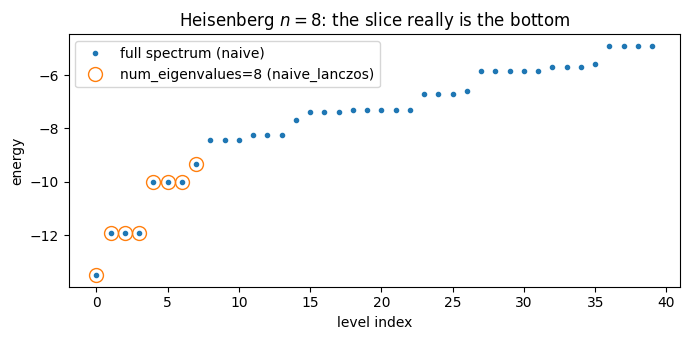

In [8]:
heis = Heisenberg1D(8, J=1.0, h=0.0)
full = spectrum(heis)
low = spectrum(heis, method="naive_lanczos", num_eigenvalues=8)

print("max |naive_lanczos - naive| over the lowest 8:", np.max(np.abs(low - full[:8])))

plt.figure(figsize=(7, 3.5))
plt.plot(full[:40], ".", label="full spectrum (naive)")
plt.plot(low, "o", mfc="none", ms=10, label="num_eigenvalues=8 (naive_lanczos)")
plt.xlabel("level index"); plt.ylabel("energy")
plt.title("Heisenberg $n=8$: the slice really is the bottom"); plt.legend()
plt.tight_layout(); plt.show()

Degeneracy caveat: for a degenerate level either method returns *some* vector spanning the
ground subspace, not a canonical one. Compare energies, not vectors.

## 5. Sector restriction is a real saving

Restricting to fixed particle number diagonalizes a $\binom{n}{k}$ block instead of the full
$2^n$ one.

In [9]:
from math import comb

fh = FermiHubbard1D(num_fermionic_sites=3, t=1.0, U=2.0)
encoding = FermionicEncoding("jordan_wigner", num_modes=6)
restricted = fermionic_spectrum(fh, encoding, fixed_particle_number=3)
print(f"full space 2^6 = 64,   half-filled block = {len(restricted)}  (expected {comb(6, 3)})")

# the sector's levels are a subset of the full spectrum
full = fermionic_spectrum(fh, encoding)
print("every sector level appears in the full spectrum:",
      all(np.min(np.abs(full - level)) < 1e-9 for level in restricted))

full space 2^6 = 64,   half-filled block = 20  (expected 20)
every sector level appears in the full spectrum: True


## 6. The reserved `"lanczos"` method

`"lanczos"` names the matrix-free solver: apply the Hamiltonian's terms to Krylov vectors
directly, never forming the matrix. That is $O(\text{num terms} \cdot 2^n)$ time and $O(2^n)$
memory per matvec, against $O(4^n)$ for both today. It is not implemented, and says so.

In [10]:
try:
    ground_state(TFI(4), method="lanczos")
except NotImplementedError as err:
    print("NotImplementedError:", err)

NotImplementedError: method='lanczos' (matrix-free) is not implemented yet; use 'naive_lanczos'.
